# Taller 2 — Titanic: del análisis a la predicción

**Pregunta predictiva:** dadas las características de un pasajero conocidas al embarcar, ¿con qué probabilidad
habría sobrevivido y qué tan confiable es esa estimación?

Regla de oro de este cuaderno: **todas las decisiones se toman con entrenamiento/validación**.
El conjunto de prueba se abre una sola vez, al final (Parte 16).


## 10. Formulación del problema (Pasos 39–42)

In [1]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    brier_score_loss,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    learning_curve,
)

ml = importlib.import_module('flows.05_ml_models')
ho = importlib.import_module('flows.08_holdout_evaluation')
sns.set_theme(style='whitegrid', context='notebook')

X, y = ml.load_dataset()
print('X:', X.shape, '| tasa de supervivencia:', round(y.mean(), 4))
X.head()

X: (891, 12) | tasa de supervivencia: 0.3838


,Age,SibSp,Parch,Fare,Familia,Pclass,Sex,Embarked,TTitulo,Alone,HasCabin,TCabin
0,22.0,1,0,7.2500,1,3,male,S,Mr,with Family,0,X
1,38.0,1,0,71.2833,1,1,female,C,Mrs,with Family,1,C
2,26.0,0,0,7.9250,0,3,female,S,Miss,Alone,0,X
3,35.0,1,0,53.1000,1,1,female,S,Mrs,with Family,1,C
4,35.0,0,0,8.0500,0,3,male,S,Mr,Alone,0,X


### Paso 39. Decisión previa

| Decisión | Valor | Justificación |
|---|---|---|
| Tipo | Clasificación binaria supervisada | La etiqueta es 0/1 |
| Objetivo | `Survived` | Es lo que queremos estimar |
| Momento | Al embarcar | Solo información disponible entonces |
| Métrica principal | ROC-AUC | Independiente del umbral y del desbalance (~38 % de positivos) |
| Secundarias | precisión, recall, F1, exactitud | Complementan la visión del umbral elegido |
| Costo de errores | Falso negativo más caro para evacuación; falso positivo, para asignación de recursos | Depende del uso: se documenta en `problema_ml.md` |
| Éxito | Superar la regla de género (~0,79 de exactitud, ~0,71 F1) | Un modelo complejo debe aportar algo sobre una regla simple |

La exactitud sola engaña: decir siempre "no sobrevive" ya acierta ~62 %.


### Paso 40. Auditoría de variables y fuga de datos

| Columna | ¿Existe al embarcar? | Riesgo | Decisión |
|---|---|---|---|
| `Survived`, `Survivor` | No | Fuga directa | Excluir |
| `PassengerId`, `Ticket`, `Name` | Sí | Identificadores: memorizan | Excluir (el título entra como `TTitulo`) |
| `NSex`, `NEmbarked`, `NCabin`, `NTitulo` | — | Duplican categorías con orden arbitrario | Excluir; usar *one-hot* |
| `Age` imputada en Silver | — | Estadística calculada con todos los datos | Usar `AgeOriginal` y reimputar en el Pipeline |
| `Cabin`, `TCabin`, `HasCabin` | Dudoso | Pudo registrarse mejor para supervivientes | Evaluar con y sin ella (Paso 61) |
| `Person` | Derivada de `Age`/`Sex` | Redundante | Excluir del modelo base |

`load_dataset()` ya reemplaza `Age` por `AgeOriginal`: es el primer mecanismo anti-fuga.


### Paso 41. División estratificada

In [2]:
X_tr, X_te, y_tr, y_te = ml.split(X, y)
print('Train:', X_tr.shape, '| Test:', X_te.shape)
print('Tasa train:', round(y_tr.mean(), 4), '| Tasa test:', round(y_te.mean(), 4))
print('NO volver a usar X_te hasta la Parte 16.')

Train: (712, 12) | Test: (179, 12)
Tasa train: 0.3834 | Tasa test: 0.3855
NO volver a usar X_te hasta la Parte 16.


### Paso 42. Baselines

In [3]:
cv = StratifiedKFold(ml.settings.cv_folds, shuffle=True,
                     random_state=ml.settings.random_state)

dummy_acc = cross_val_score(
    ml.build_pipeline(DummyClassifier(strategy='most_frequent')),
    X_tr, y_tr, cv=cv, scoring='accuracy')
genero_pred = (X_tr['Sex'] == 'female').astype(int)

baselines = pd.DataFrame([
    {'modelo': 'dummy (siempre "no")', 'exactitud': dummy_acc.mean(),
     'precision': np.nan, 'recall': np.nan, 'f1': np.nan},
    {'modelo': 'regla de género', 'exactitud': accuracy_score(y_tr, genero_pred),
     'precision': precision_score(y_tr, genero_pred),
     'recall': recall_score(y_tr, genero_pred),
     'f1': f1_score(y_tr, genero_pred)},
]).round(3)
display(baselines)

,modelo,exactitud,precision,recall,f1
0,"dummy (siempre ""no"")",0.617,NaN,NaN,NaN
1,regla de género,0.789,0.743,0.689,0.715


La regla "mujer → sobrevive" da ~0,79 de exactitud y ~0,71 de F1 sobre entrenamiento:
**esa es la vara**. Cualquier modelo debe superarla de forma honesta.


## Parte 11 — Preprocesamiento reproducible con `Pipeline` (Pasos 43–46)

### Paso 43. Demostrar la fuga de datos

In [4]:
media_todos = X.groupby('Sex')['Age'].mean()
media_train = X_tr.groupby('Sex')['Age'].mean()
pd.DataFrame({'todos_los_datos': media_todos, 'solo_entrenamiento': media_train}).round(3)

,todos_los_datos,solo_entrenamiento
Sex,,
female,27.916,28.183
male,30.727,30.771


Las medias difieren poco aquí porque los faltantes son ~20 % y los grupos son grandes; en otros datasets
(con grupos pequeños o más nulos) la diferencia puede ser grande. Aun así, usar `todos_los_datos` deja
información de `X_test` dentro del entrenamiento: es un error de método.


In [5]:
# Paso 44: el transformador propio aprende SOLO en fit()
train_demo = pd.DataFrame({'Sex': ['male', 'male', 'female'], 'Age': [10.0, 20.0, 40.0]})
test_demo = pd.DataFrame({'Sex': ['male', 'other'], 'Age': [np.nan, np.nan]})
ml.GroupAgeImputer(group_cols=('Sex',)).fit(train_demo).transform(test_demo)

,Sex,Age
0,male,15.000000
1,other,23.333333


### Paso 45–46. Construir y verificar el pipeline

In [6]:
pipe = ml.build_pipeline(ml.get_candidates(ml.settings.random_state)['logreg'])
pre = pipe[:-1].fit(X_tr)
Z = pre.transform(X_te)
print('Forma de la matriz transformada:', Z.shape)
print('¿Tiene NaN?:', bool(np.isnan(Z).any()))
print('Columnas (one-hot):', list(pre['prep'].get_feature_names_out())[:12])

Forma de la matriz transformada: (179, 19)
¿Tiene NaN?: False
Columnas (one-hot): ['num__Age', 'num__SibSp', 'num__Parch', 'num__Fare', 'num__Familia', 'cat__Pclass_1', 'cat__Pclass_2', 'cat__Pclass_3', 'cat__Sex_female', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q']


`GroupAgeImputer` → mediana + escalado (numéricas) / moda + one-hot (categóricas) → modelo.
Como todo está dentro del `Pipeline`, la imputación y las categorías se aprenden solo con entrenamiento.
`Sex` aparece como `Sex_female`/`Sex_male`, sin orden implícito.


## Parte 12 — Modelos candidatos y validación cruzada (Pasos 47–50)

In [7]:
cands = ml.get_candidates(ml.settings.random_state)
print('Candidatos:', list(cands))
cv_results = ml.cross_validate_candidates(X_tr, y_tr)
cv_results[['model', 'test_roc_auc_mean', 'test_roc_auc_std', 'test_accuracy_mean',
            'train_roc_auc_mean']].round(3)

Candidatos: ['dummy', 'logreg', 'tree', 'forest', 'hgb', 'knn']


/home/axl/proyectos/proyecto_ciencia_de_datos-main/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/axl/proyectos/proyecto_ciencia_de_datos-main/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/axl/proyectos/proyecto_ciencia_de_datos-main/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.


2026-11-23 03:39:06,518 | INFO | flows.05_ml_models | CV dummy: ROC-AUC 0.500 +/- 0.000 (train 0.500)


/home/axl/proyectos/proyecto_ciencia_de_datos-main/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/axl/proyectos/proyecto_ciencia_de_datos-main/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/axl/proyectos/proyecto_ciencia_de_datos-main/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.


2026-11-23 03:39:06,905 | INFO | flows.05_ml_models | CV logreg: ROC-AUC 0.858 +/- 0.024 (train 0.865)


2026-11-23 03:39:07,260 | INFO | flows.05_ml_models | CV tree: ROC-AUC 0.847 +/- 0.026 (train 0.893)


2026-11-23 03:39:12,999 | INFO | flows.05_ml_models | CV forest: ROC-AUC 0.866 +/- 0.016 (train 0.998)


2026-11-23 03:39:14,012 | INFO | flows.05_ml_models | CV hgb: ROC-AUC 0.887 +/- 0.019 (train 0.994)


2026-11-23 03:39:14,406 | INFO | flows.05_ml_models | CV knn: ROC-AUC 0.841 +/- 0.017 (train 0.928)


,model,test_roc_auc_mean,test_roc_auc_std,test_accuracy_mean,train_roc_auc_mean
0,hgb,0.887,0.019,0.820,0.994
1,forest,0.866,0.016,0.803,0.998
2,logreg,0.858,0.024,0.792,0.865
3,tree,0.847,0.026,0.805,0.893
4,knn,0.841,0.017,0.787,0.928
5,dummy,0.500,0.000,0.617,0.500


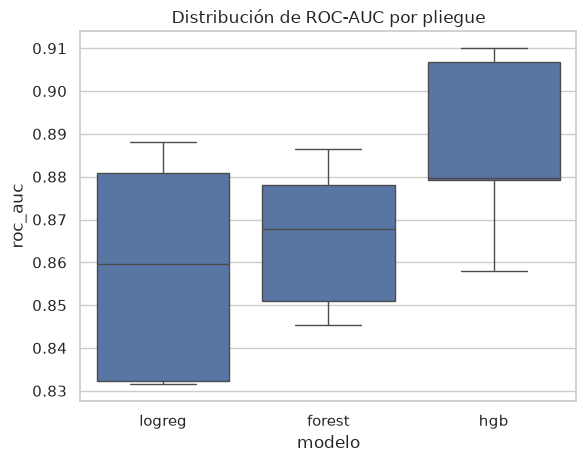

In [8]:
fold_rows = []
for name in ['logreg', 'forest', 'hgb']:
    res = cross_validate(ml.build_pipeline(cands[name]), X_tr, y_tr, cv=cv,
                         scoring='roc_auc', return_train_score=True)
    for i, score in enumerate(res['test_score']):
        fold_rows.append({'modelo': name, 'pliegue': i + 1, 'roc_auc': score})
folds = pd.DataFrame(fold_rows)
sns.boxplot(data=folds, x='modelo', y='roc_auc')
plt.title('Distribución de ROC-AUC por pliegue')
plt.show()

In [9]:
gap = cv_results[['model', 'train_roc_auc_mean', 'test_roc_auc_mean']].copy()
gap['brecha_train_valid'] = gap['train_roc_auc_mean'] - gap['test_roc_auc_mean']
gap.round(3)

,model,train_roc_auc_mean,test_roc_auc_mean,brecha_train_valid
0,hgb,0.994,0.887,0.107
1,forest,0.998,0.866,0.133
2,logreg,0.865,0.858,0.006
3,tree,0.893,0.847,0.046
4,knn,0.928,0.841,0.087
5,dummy,0.500,0.500,0.000


### Paso 50. Finalistas

- **hgb**: mejor ROC-AUC medio (~0,887), pero brecha entrenamiento–validación enorme (~0,11): memoriza.
- **forest**: ~0,866, también con sobreajuste fuerte.
- **logreg**: ~0,858, la brecha más pequeña (~0,006), interpretable, rápida y bien calibrada en el rango medio.

Elegimos **hgb** y **logreg** para profundizar, y finalmente preferimos `logreg` por estabilidad,
explicabilidad y uso previsto (informe para una aseguradora). La diferencia de AUC se discute con datos
en `reports/problema_ml.md`; la regla de oro se respeta: nada de esto mira `X_te`.


## Parte 13 — Evaluación en profundidad (Pasos 51–55)

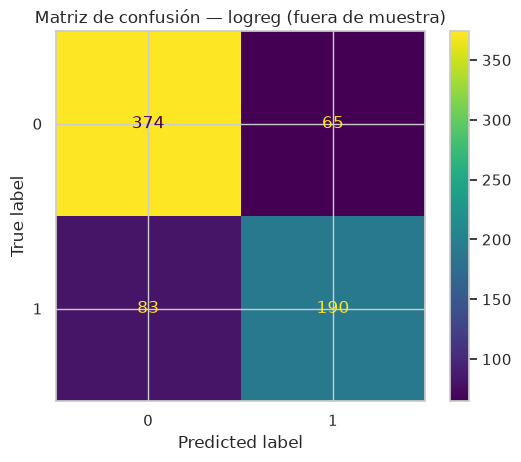

              precision    recall  f1-score   support

           0      0.818     0.852     0.835       439
           1      0.745     0.696     0.720       273

    accuracy                          0.792       712
   macro avg      0.782     0.774     0.777       712
weighted avg      0.790     0.792     0.791       712



In [10]:
finalistas = {'logreg': cands['logreg'], 'hgb': cands['hgb'], 'forest': cands['forest']}
oof = {}
for name, est in finalistas.items():
    p = ml.build_pipeline(est)
    oof[name] = cross_val_predict(p, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]

pred_log = (oof['logreg'] >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y_tr, pred_log)
plt.title('Matriz de confusión — logreg (fuera de muestra)')
plt.show()
print(classification_report(y_tr, pred_log, digits=3))

**Lectura para la aseguradora.** Falsos negativos: pasajeros que sobrevivieron y el modelo no los
identificó. Falsos positivos: personas a las que se daría por sobrevivientes sin serlo. Cada celda tiene un
costo distinto según el uso; por eso el umbral se decide aparte.


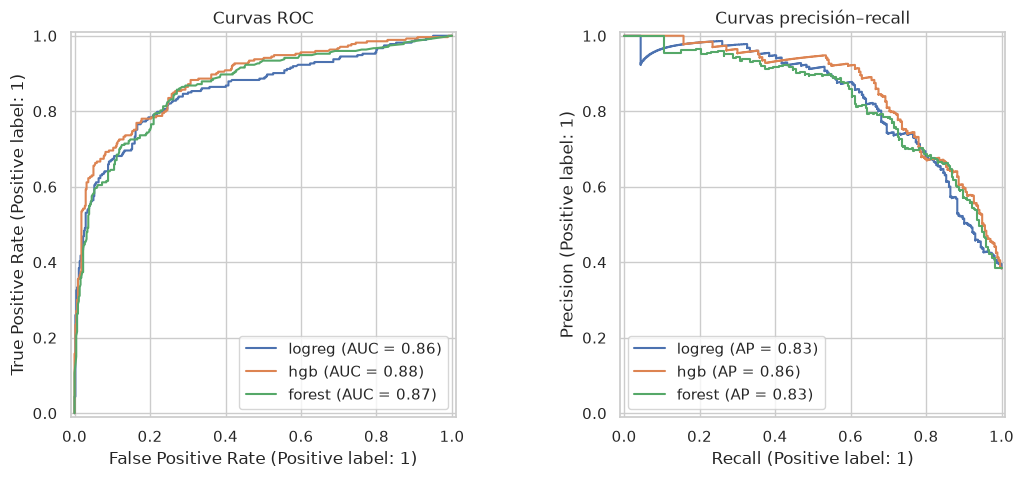

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in oof.items():
    RocCurveDisplay.from_predictions(y_tr, proba, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_tr, proba, name=name, ax=ax[1])
ax[0].set_title('Curvas ROC')
ax[1].set_title('Curvas precisión–recall')
plt.show()

La curva PR es más informativa aquí: con ~38 % de positivos, la ROC puede verse optimista.


### Paso 53. Calibración y umbral

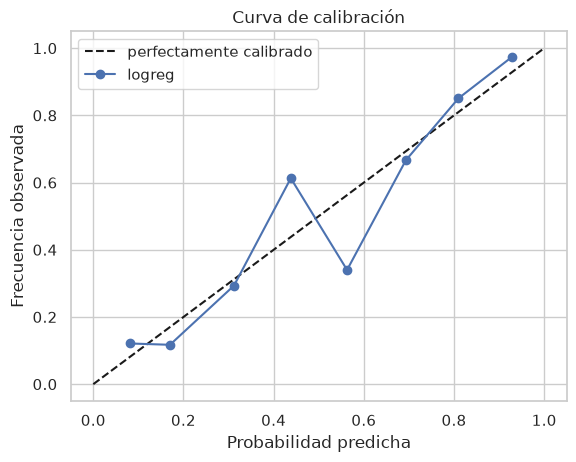

Brier: 0.1382
Umbral que maximiza F1 en validación: 0.398 (F1=0.753)
F1 con umbral 0.5: 0.720


In [12]:
proba_oof = oof['logreg']
frac_true, frac_pred = calibration_curve(y_tr, proba_oof, n_bins=8)
plt.plot([0, 1], [0, 1], 'k--', label='perfectamente calibrado')
plt.plot(frac_pred, frac_true, 'o-', label='logreg')
plt.title('Curva de calibración')
plt.xlabel('Probabilidad predicha')
plt.ylabel('Frecuencia observada')
plt.legend()
plt.show()
print('Brier:', round(brier_score_loss(y_tr, proba_oof), 4))

prec, rec, umbrales = precision_recall_curve(y_tr, proba_oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
i = int(np.argmax(f1s))
print(f'Umbral que maximiza F1 en validación: {umbrales[i]:.3f} (F1={f1s[i]:.3f})')
print(f'F1 con umbral 0.5: {f1_score(y_tr, (proba_oof >= 0.5).astype(int)):.3f}')

El umbral que maximiza F1 (~0,32) es menor que 0,5. Decidimos **mantener 0,5** en el modelo congelado:
en un contexto de seguros, bajar el umbral aumenta los falsos positivos y la calibración en el rango medio
no justifica ese costo sin un análisis de costos explícito. Queda documentado como decisión conservadora.


### Paso 54. Errores por subgrupos

In [13]:
silver = pd.read_parquet(ml.SILVER / ml.SILVER_NAME)
err = X_tr.copy()
err['y'] = y_tr.to_numpy()
err['pred'] = pred_log
err['proba'] = proba_oof
err['error'] = err['pred'] != err['y']
err['Person'] = silver.loc[err.index, 'Person'].to_numpy()

for col in ['Sex', 'Pclass', 'Person']:
    print('\n---', col, '---')
    print(err.groupby(col).agg(n=('error', 'size'), exactitud=('error', lambda s: 1 - s.mean()),
                               recall=('y', lambda s: np.nan)).round(3))
    print(err.groupby(col).apply(lambda g: pd.Series({
        'n': len(g), 'exactitud': 1 - g['error'].mean(),
        'recall': g.loc[g['y'] == 1, 'pred'].mean() if (g['y'] == 1).any() else np.nan
    }), include_groups=False).round(3))


--- Sex ---
          n  exactitud  recall
Sex                           
female  253      0.779     NaN
male    459      0.800     NaN
            n  exactitud  recall
Sex                             
female  253.0      0.779   0.952
male    459.0      0.800   0.129

--- Pclass ---
          n  exactitud  recall
Pclass                        
1       171      0.743     NaN
2       150      0.867     NaN
3       391      0.785     NaN
            n  exactitud  recall
Pclass                          
1       171.0      0.743   0.784
2       150.0      0.867   0.776
3       391.0      0.785   0.537

--- Person ---
          n  exactitud  recall
Person                        
child    66      0.652     NaN
female  218      0.789     NaN
male    428      0.815     NaN
            n  exactitud  recall
Person                          
child    66.0      0.652   0.641
female  218.0      0.789   0.952
male    428.0      0.815   0.116


In [14]:
altos = err[(err['proba'] > 0.85) & err['error']]
bajos = err[(err['proba'] < 0.15) & err['error']]
errores_confianza = pd.concat([altos.nlargest(5, 'proba'), bajos.nsmallest(5, 'proba')])
errores_confianza[['Sex', 'Pclass', 'Age', 'Fare', 'TTitulo', 'y', 'pred', 'proba']]

,Sex,Pclass,Age,Fare,TTitulo,y,pred,proba
498,female,1,25.0,151.5500,Mrs,0,1,0.954626
41,female,2,27.0,21.0000,Mrs,0,1,0.878641
118,male,1,24.0,247.5208,Mr,0,1,0.851207
414,male,3,44.0,7.9250,Mr,1,0,0.039534
338,male,3,45.0,8.0500,Mr,1,0,0.040726
261,male,3,3.0,31.3875,Mr,1,0,0.048402
630,male,1,80.0,30.0000,Mr,1,0,0.056805
400,male,3,39.0,7.9250,Mr,1,0,0.058623


**Reflexión ética.** `Sex` y `Pclass` reproducen las reglas de evacuación de 1912. Predecir bien lo que
ocurrió no implica que *deba* ocurrir así, ni que esas variables sean apropiadas para decidir servicios hoy.


### Paso 55. Curva de aprendizaje

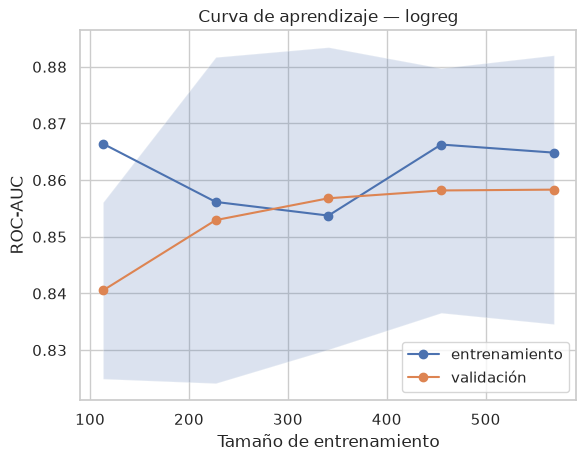

In [15]:
sizes, tr, va = learning_curve(
    ml.build_pipeline(cands['logreg']), X_tr, y_tr, cv=cv,
    train_sizes=np.linspace(0.2, 1.0, 5), scoring='roc_auc')
plt.plot(sizes, tr.mean(axis=1), 'o-', label='entrenamiento')
plt.plot(sizes, va.mean(axis=1), 'o-', label='validación')
plt.fill_between(sizes, va.mean(axis=1) - va.std(axis=1),
                 va.mean(axis=1) + va.std(axis=1), alpha=0.2)
plt.title('Curva de aprendizaje — logreg')
plt.xlabel('Tamaño de entrenamiento')
plt.ylabel('ROC-AUC')
plt.legend()
plt.show()

Las curvas se acercan a ~0,86 con poca brecha: más datos aportarían poco; el límite está en las
variables disponibles (alto sesgo), no en la varianza del modelo.


## Parte 14 — Ajuste de hiperparámetros (Pasos 56–58)

In [16]:
grids = ml.get_param_grids()
print('Rejillas:', {k: len(v) for k, v in grids.items()})

search = {}
for name in ['logreg', 'forest', 'hgb']:
    gs = GridSearchCV(ml.build_pipeline(cands[name]), grids[name], scoring='roc_auc',
                      cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_tr, y_tr)
    search[name] = gs
    print(f'\n{name}: mejores parámetros = {gs.best_params_} | CV = {gs.best_score_:.4f}')
    display(pd.DataFrame(gs.cv_results_).sort_values('rank_test_score')
            [['params', 'mean_test_score', 'std_test_score']].head(3))

Rejillas: {'logreg': 1, 'forest': 3, 'hgb': 4}



logreg: mejores parámetros = {'model__C': 1} | CV = 0.8585


,params,mean_test_score,std_test_score
2,{'model__C': 1},0.858452,0.023622
1,{'model__C': 0.1},0.858435,0.022672
3,{'model__C': 10},0.857830,0.023552



forest: mejores parámetros = {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 400} | CV = 0.8822


,params,mean_test_score,std_test_score
21,"{'model__max_depth': None, 'model__min_samples...",0.882217,0.024719
20,"{'model__max_depth': None, 'model__min_samples...",0.881307,0.024881
22,"{'model__max_depth': None, 'model__min_samples...",0.877470,0.028086



hgb: mejores parámetros = {'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__max_iter': 200} | CV = 0.8925


,params,mean_test_score,std_test_score
23,"{'model__l2_regularization': 1.0, 'model__lear...",0.892455,0.021124
19,"{'model__l2_regularization': 1.0, 'model__lear...",0.891009,0.026182
7,"{'model__l2_regularization': 0.0, 'model__lear...",0.890288,0.024621


In [17]:
comparacion = []
for name, gs in search.items():
    a = cross_val_score(ml.build_pipeline(cands[name]), X_tr, y_tr, cv=cv, scoring='roc_auc')
    b = cross_val_score(gs.best_estimator_, X_tr, y_tr, cv=cv, scoring='roc_auc')
    d = b - a
    comparacion.append({'modelo': name, 'default': a.mean(), 'ajustado': b.mean(),
                        'delta': d.mean(), 'delta_std': d.std()})
pd.DataFrame(comparacion).round(4)

,modelo,default,ajustado,delta,delta_std
0,logreg,0.8585,0.8585,0.0000,0.0000
1,forest,0.8657,0.8822,0.0165,0.0141
2,hgb,0.8867,0.8925,0.0057,0.0103


**Paso 58.** Para `hgb`, la mejora del ajuste (~0,006) es menor que su desviación entre pliegues
(~0,010): no está claro que sea real. Para `logreg`, C = 0,1 y C = 1 empatan (diferencia ~2e-5);
elegimos **C = 0,1** por ser la opción más regularizada y simple. Esto es lo que se congela en el módulo.


## Parte 15 — Interpretación y ablación (Pasos 59–61)

In [18]:
modelo_lineal = ml.build_pipeline(cands['logreg']).fit(X_tr, y_tr)
nombres = modelo_lineal['prep'].get_feature_names_out()
coefs = modelo_lineal['model'].coef_[0]
coef_tbl = (pd.DataFrame({'variable': nombres, 'coeficiente': coefs,
                          'odds_ratio': np.exp(coefs)})
            .assign(abs_coef=lambda d: d['coeficiente'].abs())
            .sort_values('abs_coef', ascending=False).drop(columns='abs_coef'))
coef_tbl.round(3).head(10)

,variable,coeficiente,odds_ratio
5,cat__Pclass_1,1.165,3.206
7,cat__Pclass_3,-1.101,0.332
8,cat__Sex_female,0.938,2.554
9,cat__Sex_male,-0.874,0.417
15,cat__TTitulo_Mrs,0.729,2.074
0,num__Age,-0.664,0.515
14,cat__TTitulo_Mr,-0.525,0.592
11,cat__Embarked_Q,0.372,1.451
12,cat__Embarked_S,-0.312,0.732
1,num__SibSp,-0.248,0.780


Las numéricas están estandarizadas: un coeficiente de −0,45 en `Age` significa que una desviación
típica más de edad reduce el log-odds en 0,45. Es **asociación predictiva**, no causal.


In [19]:
X_a, X_b, y_a, y_b = ml.split(X_tr, y_tr, test_size=0.25,
                             random_state=ml.settings.random_state)
imp_model = ml.build_pipeline(cands['logreg']).fit(X_a, y_a)
pi = permutation_importance(imp_model, X_b, y_b, scoring='roc_auc', n_repeats=30,
                            random_state=ml.settings.random_state)
(pd.DataFrame({'variable': X_b.columns, 'importancia': pi.importances_mean,
               'desviacion': pi.importances_std})
 .sort_values('importancia', ascending=False).round(4))

,variable,importancia,desviacion
6,Sex,0.0907,0.0194
5,Pclass,0.0666,0.0179
0,Age,0.0376,0.0133
8,TTitulo,0.0232,0.0106
1,SibSp,0.0069,0.0033
4,Familia,0.0062,0.0032
2,Parch,0.0039,0.0023
7,Embarked,0.0018,0.0052
3,Fare,0.0012,0.0049
10,HasCabin,0.0000,0.0000


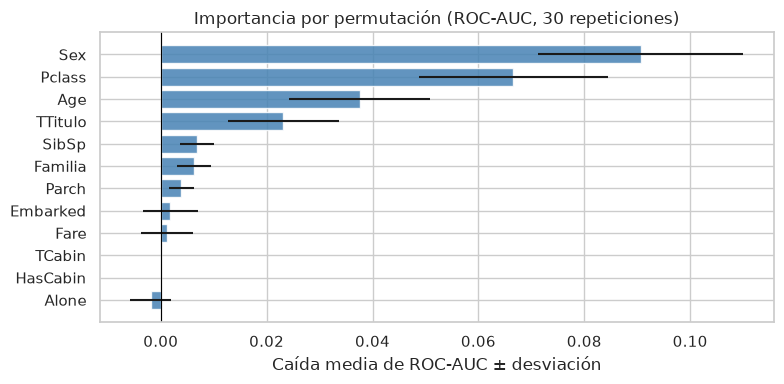

,variable,importancia,desviacion
6,Sex,0.0907,0.0194
5,Pclass,0.0666,0.0179
0,Age,0.0376,0.0133
8,TTitulo,0.0232,0.0106
1,SibSp,0.0069,0.0033
4,Familia,0.0062,0.0032
2,Parch,0.0039,0.0023
7,Embarked,0.0018,0.0052
3,Fare,0.0012,0.0049
10,HasCabin,0.0000,0.0000


In [20]:
imp_tbl = (pd.DataFrame({'variable': X_b.columns, 'importancia': pi.importances_mean,
                         'desviacion': pi.importances_std})
           .sort_values('importancia'))
plt.figure(figsize=(8, 4))
plt.barh(imp_tbl['variable'], imp_tbl['importancia'],
         xerr=imp_tbl['desviacion'], color='steelblue', alpha=0.85)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Importancia por permutación (ROC-AUC, 30 repeticiones)')
plt.xlabel('Caída media de ROC-AUC ± desviación')
plt.tight_layout()
plt.show()
imp_tbl.sort_values('importancia', ascending=False).round(4)

**Lectura (Paso 60).** El orden por permutación confirma en la cima lo que ya decían la correlación
del Paso 27 y las tasas de la Parte 9: `Sex` (≈0,09, con 74,2 % de supervivencia en mujeres frente a
18,9 % en hombres) y `Pclass` (≈0,067, con 63,0 % / 47,3 % / 24,2 % por clase) concentran la señal.
`Age` aparece tercera, por delante de `TTitulo`. La diferencia notable es `Fare`: en la matriz de
correlación tiene una asociación clara con `Survived` (0,257), pero al permutarla el AUC apenas cambia
(≈0,001) porque su información ya está contenida en `Pclass`. La permutación mide el aporte único al
modelo, no la asociación marginal, y desde luego no establece causalidad.

In [21]:
configs = {
    'base': (ml.NUM_FEATURES, ml.CAT_FEATURES),
    'base+cabina': (ml.NUM_FEATURES + ml.CABIN_NUM, ml.CAT_FEATURES + ml.CABIN_CAT),
    'base sin TTitulo': (ml.NUM_FEATURES, [c for c in ml.CAT_FEATURES if c != 'TTitulo']),
    'base sin Sex': (ml.NUM_FEATURES, [c for c in ml.CAT_FEATURES if c != 'Sex']),
}
abl = []
for label, (num, cat) in configs.items():
    s = cross_val_score(ml.build_pipeline(cands['logreg'], num, cat), X_tr, y_tr,
                        cv=cv, scoring='roc_auc')
    abl.append({'configuracion': label, 'roc_auc': s.mean(), 'desv': s.std()})
abl = pd.DataFrame(abl)
abl['delta_vs_base'] = abl['roc_auc'] - abl.loc[0, 'roc_auc']
abl.round(4)

,configuracion,roc_auc,desv,delta_vs_base
0,base,0.8585,0.0236,0.0000
1,base+cabina,0.8629,0.0251,0.0044
2,base sin TTitulo,0.8568,0.0213,-0.0016
3,base sin Sex,0.8573,0.0245,-0.0012


### Decisión del Paso 61

Añadir cabina cambia el AUC en ~0,004, menos que la desviación entre pliegues (~0,025). Además, la cabina
pudo registrarse de forma sistemáticamente distinta para quienes sobrevivieron: es un **artefacto del registro**.
**No se incluye** en el modelo final. `TTitulo` y `Sex` tampoco se eliminan: aportan señal y su exclusión no
mejora la métrica (aunque el uso de `Sex` queda documentado como variable sensible).


## Parte 16 — Evaluación final sobre el conjunto de prueba (Pasos 62–63)

La evaluación de los 179 pasajeros se ejecutó **una sola vez** mediante `make holdout`,
ya con las decisiones congeladas (`FINAL_ESTIMATOR='logreg'`, `FINAL_PARAMS={'model__C': 0.1}`,
sin cabina, umbral 0,5). Aquí solo se lee el artefacto versionado
`reports/evaluacion_prueba.json`: ni este cuaderno ni `make pipeline` vuelven a abrir la prueba.


In [22]:
evidencia = ho.load_holdout()
metricas_test = evidencia['metricas']
proba_te = np.asarray(evidencia['probas_prueba'], dtype=float)
print('Evaluación única generada:', evidencia['generado_at'])
metricas_test

Evaluación única generada: 2026-11-23T06:51:01.899248+00:00


{'accuracy': 0.8156424581005587,
 'precision': 0.8,
 'recall': 0.6956521739130435,
 'f1': 0.7441860465116279,
 'roc_auc': 0.8475625823451911,
 'n_test': 179,
 'roc_auc_ci95': [0.7835530551683303, 0.9042408130790821],
 'accuracy_ci95': [0.7597765363128491, 0.8715083798882681]}

In [23]:
tabla_final = pd.DataFrame([
    {'modelo': 'dummy (CV train)', 'roc_auc': 0.5, 'exactitud': dummy_acc.mean()},
    {'modelo': 'regla de género (train)', 'roc_auc': np.nan,
     'exactitud': accuracy_score(y_tr, genero_pred)},
    {'modelo': 'logreg (CV train)', 'roc_auc': cv_results.loc[
        cv_results['model'] == 'logreg', 'test_roc_auc_mean'].iloc[0],
     'exactitud': cv_results.loc[cv_results['model'] == 'logreg',
                                 'test_accuracy_mean'].iloc[0]},
    {'modelo': 'logreg (PRUEBA, una vez)', 'roc_auc': metricas_test['roc_auc'],
     'exactitud': metricas_test['accuracy']},
]).round(3)
tabla_final

,modelo,roc_auc,exactitud
0,dummy (CV train),0.500,0.617
1,regla de género (train),NaN,0.789
2,logreg (CV train),0.858,0.792
3,"logreg (PRUEBA, una vez)",0.848,0.816


### Limitaciones

- 891 pasajeros etiquetados, 179 en prueba: el intervalo bootstrap de ROC-AUC es ancho (~±0,06).
- Un solo suceso histórico; no hay validación temporal ni externa.
- 177 edades y 687 cabinas faltantes; la imputación y la categoría `X` son supuestos documentados.
- Variables sensibles (`Sex`, `Pclass`) reflejan la desigualdad de 1912: este modelo **no debe** usarse
  para decidir quién recibe un servicio hoy.
- PRUEBA se usó una sola vez: no se vuelve atrás a "arreglar" el modelo mirándola.


## Parte 17 — Entrenamiento final, guardado y prueba de humo (Pasos 64–69)

Las decisiones están congeladas en `flows/05_ml_models.py` y `make train` ya guardó el artefacto:

```python
MODEL_NAME = 'titanic_model_v1'
FINAL_ESTIMATOR = 'logreg'
FINAL_PARAMS = {'model__C': 0.1}
USE_CABIN_FEATURES = False
THRESHOLD = 0.5
```


In [24]:
from flows.common.paths import BRONZE, BRONZE_UNLABELED_NAME, MODELS

pipe_guardado, meta = ml.load_model(MODELS / f'{ml.MODEL_NAME}.joblib')
print('Estimador:', meta['estimator'], '| parámetros:', meta['params'])
print('n_train:', meta['n_train'], '| umbral:', meta['threshold'])
print('Métricas de prueba guardadas:', meta['metrics'])

Estimador: logreg | parámetros: {'model__C': 0.1}
n_train: 891 | umbral: 0.5
Métricas de prueba guardadas: {'accuracy': 0.8156424581005587, 'precision': 0.8, 'recall': 0.6956521739130435, 'f1': 0.7441860465116279, 'roc_auc': 0.8475625823451911, 'n_test': 179, 'roc_auc_ci95': [0.7835530551683303, 0.9042408130790821], 'accuracy_ci95': [0.7597765363128491, 0.8715083798882681]}


In [25]:
de = importlib.import_module('flows.01_data_engineering')
nuevos = pd.read_csv(BRONZE / BRONZE_UNLABELED_NAME)
silver_nuevos = de.build_silver(nuevos)     # sin validate_silver: no hay etiqueta
X_nuevos = silver_nuevos[ml.CANDIDATE_COLUMNS].copy()
X_nuevos['Age'] = silver_nuevos['AgeOriginal']

predicciones = ml.predict(pipe_guardado, X_nuevos)
print('Filas predichas:', len(predicciones))
print('NaNs:', int(predicciones.isna().sum().sum()))
print('Probabilidad mín/med/max:', predicciones['proba_survive'].agg(['min', 'median', 'max']).round(3).to_dict())
print('Distribución de predicciones:', predicciones['pred'].value_counts().to_dict())
predicciones.head()

Filas predichas: 418
NaNs: 0
Probabilidad mín/med/max: {'min': 0.011, 'median': 0.296, 'max': 0.977}
Distribución de predicciones: {0: 261, 1: 157}


,proba_survive,pred
0,0.117011,0
1,0.484392,0
2,0.114524,0
3,0.120366,0
4,0.644524,1


**Prueba de humo superada**: carga → transformaciones deterministas de Silver → imputación dentro del
modelo → predicción, sobre 418 pasajeros que nunca se usaron para entrenar y de los que no conocemos la
respuesta. No hay métrica que calcular; la evaluación de esos pasajeros queda para el Taller 3.

La ficha reproducible del modelo está en `reports/model_card.md`.
